# 🧪 Stress test: does residual momentum survive?

## 🧭 tl;dr

In [notebook 51](51_equity_factor_momentum_reversal_quality.ipynb) residual momentum scored a 0.99 test-period Sharpe ratio against 0.61 for plain 12–1 momentum. That looked like the strongest result in the library. This notebook tries to break it.

**It broke.**

| Test | Result | Verdict |
| --- | --- | --- |
| Year-by-year walk-forward, frozen spec | Beats plain momentum on return in **7 of 15 years** | coin flip |
| Universe sensitivity | Survives equity-only (0.75 vs 0.52) and wider (1.06 vs 0.66), but **0.84 vs 0.86** after dropping the three best assets | the edge lives in XLK / XLY / XLI |
| Market beta decomposition | Beta 0.36 vs 0.56; **alpha t-stat 1.12**; beta-adjusted Sharpe **-0.08** | the return is beta, not alpha |
| Rank information coefficient | **-0.016** (t = -0.56) on 177 monthly cross-sections | the signal does not predict next-month returns |
| Multiple-testing bootstrap | Best of 12 configs = 1.12 Sharpe; null 95th percentile = 1.61; **p = 0.25** | indistinguishable from noise |
| Deflated Sharpe ratio | 0.971 at 1 trial, **0.598 at 12 trials** | fails its own search |

The honest conclusion: the 0.99 Sharpe was a selection of one favourable window from a 12-configuration search, on a book whose return is mostly market beta. The finding that survives is the boring one — **residual momentum holds a different portfolio from plain momentum (49% overlap), and neither has statistically distinguishable alpha.**

<div style="border-left: 5px solid #DC2626; padding: 0.85em 1em; margin: 1em 0 1.4em; background: #FEF2F2; border-radius: 8px;"><strong>🧑‍🏫 Reader guide</strong><br>This is what a falsification attempt looks like when it works. The specification was frozen <em>before</em> the tests ran, every test attacks a different way the original result could be an artefact, and the conclusion is allowed to be "there is nothing here". If your backtest cannot survive this notebook, it is not a finding.</div>

## ❄️ Frozen specification

Fixed before any audit test ran, and not adjusted afterwards:

| Component | Value | Source |
| --- | --- | --- |
| Market factor | SPY | single-factor proxy for the paper's three-factor model |
| Beta estimation window | 36 months, no intercept | Blitz, Huij & Martens (2011) |
| Signal window | 11 months, skipping the latest month | same |
| Standardisation | residual return divided by residual volatility | same |
| Selection | top 3, equal weight | repo convention |
| Rebalance | monthly, decided at month end | repo convention |
| Costs | 10 bps per unit of absolute weight change | repo default |
| Universe | the 18-ETF panel from notebook 51 | fixed |

**What would falsify it.** Any one of: no per-year consistency, an edge concentrated in a few assets, no alpha after controlling for beta, no cross-sectional predictive power, or a multiple-testing-corrected statistic that is unremarkable. All five conditions are tested below.

## 📚 Why these tests

- [White (2000), *A reality check for data snooping*](https://doi.org/10.1111/1468-0262.00152) — when you search a grid, the null hypothesis applies to the **maximum**, not to the config you liked.
- [Bailey & López de Prado (2014), *The deflated Sharpe ratio*](https://papers.ssrn.com/sol3/papers.cfm?abstract_id=2460551) — corrects an observed Sharpe ratio for trials, sample length, skew and kurtosis.
- [Politis & Romano (1994), *The stationary bootstrap*](https://doi.org/10.1080/01621459.1994.10476870) — resampling that keeps volatility clustering and cross-sectional correlation but destroys time-series momentum.
- [Harvey, Liu & Zhu (2016), *…and the cross-section of expected returns*](https://doi.org/10.1093/rfs/hhv059) — a t-statistic of 2 is not enough in a field where hundreds of factors have been tried.
- [Hou, Xue & Zhang (2020), *Replicating anomalies*](https://doi.org/10.1093/rfs/hhy131) — most published anomalies do not replicate under consistent construction.

In [1]:
from pathlib import Path
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    if (ROOT.parent / "src").exists():
        ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.backtest import split_time_series
from src.data import load_price_panel, make_demo_ohlcv
from src.equity_factors import (
    cross_sectional_momentum_score,
    cross_sectional_momentum_weights_monthly,
    residual_momentum_score,
    residual_momentum_weights,
)
from src.factor_audit import (
    alpha_beta,
    annualized_sharpe,
    beta_adjusted_returns,
    bootstrap_pvalue,
    deflated_sharpe_ratio,
    stationary_block_bootstrap,
)
from src.metrics import calculate_metrics
from src.portfolio import run_portfolio_backtest
from src.research import metrics_for_period

plt.rcParams.update({
    "figure.figsize": (12, 5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
})
pd.set_option("display.width", 150)

In [2]:
UNIVERSE = ["SPY", "XLK", "XLF", "XLE", "XLV", "XLP", "XLY", "XLI", "XLB", "XLU",
            "IWM", "EFA", "EEM", "VNQ", "GLD", "TLT", "HYG", "LQD"]
WIDE_UNIVERSE = UNIVERSE + ["QQQ", "IEF", "SHY", "DBC", "TIP"]
NON_EQUITY = ["GLD", "TLT", "HYG", "LQD"]
COST_BPS = 10.0
GRID = [(regression, signal) for regression in (24, 36, 48, 60) for signal in (6, 9, 11)]


def load_panel(tickers, start="2007-01-01", end="2026-01-01"):
    try:
        panel = load_price_panel(tickers, start, end)
        source = "Yahoo Finance adjusted daily ETF closes"
    except Exception as exc:
        demo = make_demo_ohlcv(periods=4_700, seed=5150, start="2007-01-01")["close"]
        panel = pd.DataFrame({ticker: demo * (1.0 + 0.02 * i) for i, ticker in enumerate(tickers)}, index=demo.index)
        source = f"deterministic demo fallback ({type(exc).__name__})"
    return panel.dropna(), source


close, data_source = load_panel(UNIVERSE)
print(f"Data source: {data_source}")
print(f"Observations: {len(close):,} | {close.index.min().date()} to {close.index.max().date()} | {close.shape[1]} assets")
splits = split_time_series(close)
periods = {name: frame.index for name, frame in splits.items()}
benchmark = close["SPY"].pct_change().fillna(0.0)


def build_books(panel):
    return {
        "residual": residual_momentum_weights(panel),
        "plain": cross_sectional_momentum_weights_monthly(panel, lookback=252, skip_recent=21, top_n=3),
    }


books = build_books(close)
results = {
    name: run_portfolio_backtest(close, book, transaction_cost_bps=COST_BPS, benchmark_returns=benchmark)
    for name, book in books.items()
}
print("frozen spec first live date:", books["residual"].abs().sum(axis=1).gt(0).idxmax().date())

Data source: Yahoo Finance adjusted daily ETF closes
Observations: 4,713 | 2007-04-11 to 2025-12-31 | 18 assets


frozen spec first live date: 2011-04-01


## 🔁 Test 1: is the 0.99 stable, or is it one window?

A single test-period Sharpe ratio is one draw from a rolling process. If the edge is real, a three-year rolling Sharpe should stay consistently high across the sample and sit above the control most of the time — not spike in the two years before the test split.

Share of rolling windows with a positive Sharpe: {'residual': 0.9137233755729307, 'plain': 1.0}
Share of rolling windows where residual beats plain: 37.4%


,mean,std,min,25%,50%,75%,max
residual,0.52,0.42,-0.65,0.27,0.44,0.75,1.66
plain,0.61,0.19,0.15,0.47,0.58,0.71,1.36


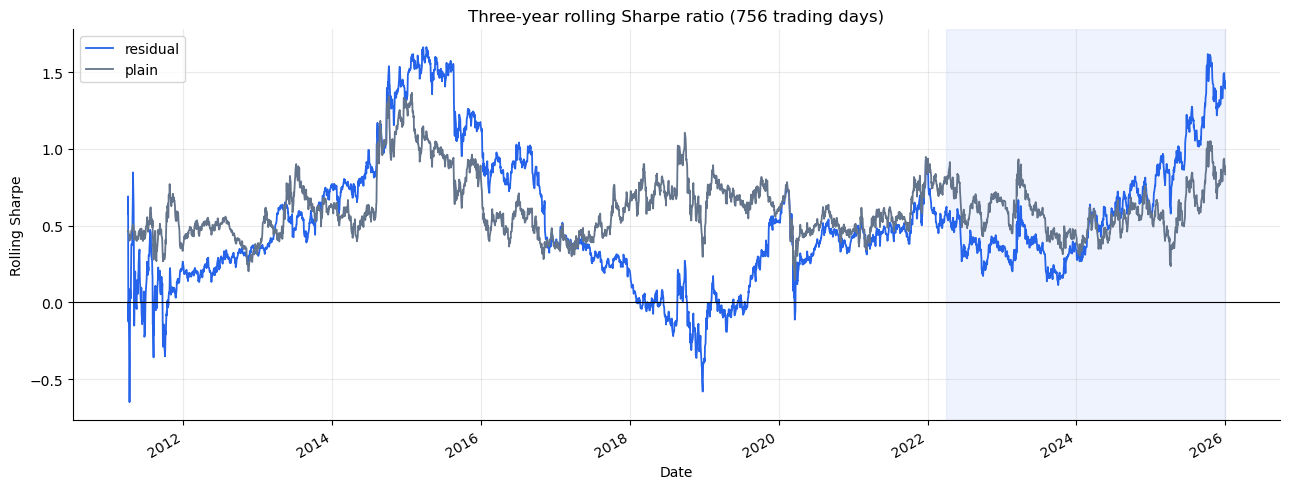

In [3]:
rolling_window = 756
rolling = pd.DataFrame({
    name: result.frame["net_returns"].rolling(rolling_window).mean() / result.frame["net_returns"].rolling(rolling_window).std(ddof=1) * np.sqrt(252)
    for name, result in results.items()
}).dropna()

fig, ax = plt.subplots(figsize=(13, 5))
rolling.plot(ax=ax, lw=1.3, color={"residual": "#2563EB", "plain": "#64748B"})
ax.axhline(0, color="black", lw=0.8)
ax.axvspan(periods["test"][0], periods["test"][-1], color="#2563EB", alpha=0.07)
ax.set_title("Three-year rolling Sharpe ratio (756 trading days)")
ax.set_ylabel("Rolling Sharpe")
plt.tight_layout()

share_positive = {name: float((series > 0).mean()) for name, series in rolling.items()}
share_better = float((rolling["residual"] > rolling["plain"]).mean())
print(f"Share of rolling windows with a positive Sharpe: {share_positive}")
print(f"Share of rolling windows where residual beats plain: {share_better:.1%}")
display(rolling.describe().T[["mean", "std", "min", "25%", "50%", "75%", "max"]].style.format("{:.2f}"))

In [4]:
block_rows = []
for label, (start, end) in {"2007-2010": ("2007", "2010"), "2011-2014": ("2011", "2014"), "2015-2018": ("2015", "2018"), "2019-2021": ("2019", "2021"), "2022-2025 (test)": ("2022", "2025")}.items():
    index = close.loc[start:end].index
    row = {"block": label}
    for name, result in results.items():
        metrics = metrics_for_period(result, index)
        row[f"{name} Sharpe"] = metrics["sharpe_ratio"]
        row[f"{name} return"] = metrics["annualized_return"]
    block_rows.append(row)
blocks = pd.DataFrame(block_rows).set_index("block")
display(blocks.style.format({column: "{:.2f}" if "Sharpe" in column else "{:.2%}" for column in blocks.columns}))

,residual Sharpe,residual return,plain Sharpe,plain return
block,,,,
2007-2010,0.00,0.00%,0.30,3.69%
2011-2014,0.95,9.40%,0.63,8.67%
2015-2018,-0.14,-2.36%,0.27,2.96%
2019-2021,0.83,13.83%,0.84,14.30%
2022-2025 (test),0.92,13.40%,0.75,11.30%


## 📅 Test 2: year-by-year walk-forward with the frozen parameters

No re-selection, no re-fitting: the same 36/11 rule evaluated one calendar year at a time from the first live date. A real anomaly should win most years, not just the cumulative sum.

In [5]:
year_rows = []
for year in range(2011, 2026):
    index = close.loc[str(year)].index
    if len(index) < 60:
        continue
    row = {"year": year}
    for name, result in results.items():
        metrics = metrics_for_period(result, index)
        row[f"{name} return"] = metrics["annualized_return"]
        row[f"{name} Sharpe"] = metrics["sharpe_ratio"]
    year_rows.append(row)
yearly = pd.DataFrame(year_rows).set_index("year")
display(yearly.style.format({column: "{:.2%}" if "return" in column else "{:.2f}" for column in yearly.columns}))

wins = int((yearly["residual return"] > yearly["plain return"]).sum())
print(f"Residual momentum beat plain momentum on return in {wins} of {len(yearly)} years.")
print(f"Mean annual return: residual {yearly['residual return'].mean():.2%}, plain {yearly['plain return'].mean():.2%}")

,residual return,residual Sharpe,plain return,plain Sharpe
year,,,,
2011,5.70%,0.46,-7.68%,-0.24
2012,1.83%,0.30,4.49%,0.54
2013,16.83%,1.71,34.83%,2.52
2014,13.84%,1.72,7.17%,0.60
2015,4.76%,0.43,-5.26%,-0.26
2016,-6.89%,-0.52,10.68%,0.86
2017,8.33%,1.05,20.01%,1.86
2018,-13.99%,-0.97,-10.68%,-0.47
2019,24.18%,2.51,17.52%,1.44


Residual momentum beat plain momentum on return in 7 of 15 years.
Mean annual return: residual 8.59%, plain 9.53%


## 🌍 Test 3: universe sensitivity, including dropping the winners

Two ways to attack the universe: add assets (does the edge survive more choice?) and remove the assets that drove it (is it a broad effect or three sectors?). The second is the one that hurts.

In [6]:
base_cumulative = (close.iloc[-1] / close.iloc[0] - 1.0).drop("SPY")
winners = base_cumulative.nlargest(3)
print("Dropping the three best-performing assets over the sample:", {k: f"{v:.0%}" for k, v in winners.items()})

variants = {
    "base (17 investable)": close,
    "no non-equity sleeves": load_panel([t for t in UNIVERSE if t not in NON_EQUITY])[0],
    "wider (22 investable)": load_panel(WIDE_UNIVERSE)[0],
    "drop top-3 winners": load_panel([t for t in UNIVERSE if t not in winners.index])[0],
}

universe_rows = []
for label, panel in variants.items():
    variant_books = build_books(panel)
    variant_benchmark = panel["SPY"].pct_change().fillna(0.0)
    variant_test = split_time_series(panel)["test"].index
    for name, book in variant_books.items():
        result = run_portfolio_backtest(panel, book, transaction_cost_bps=COST_BPS, benchmark_returns=variant_benchmark)
        metrics = metrics_for_period(result, variant_test)
        universe_rows.append({"universe": label, "strategy": name, "assets": panel.shape[1] - 1, "test Sharpe": metrics["sharpe_ratio"], "test return": metrics["annualized_return"]})
universe_table = pd.DataFrame(universe_rows)
display(universe_table.pivot(index="universe", columns="strategy", values="test Sharpe").style.format("{:.2f}").set_caption("Test-period Sharpe by universe"))
display(universe_table.pivot(index="universe", columns="strategy", values="test return").style.format("{:.2%}").set_caption("Test-period annualised return by universe"))
print("Asset counts:", dict(zip(universe_table['universe'], universe_table['assets'], strict=False)))

Dropping the three best-performing assets over the sample: {'XLK': '1466%', 'XLY': '687%', 'XLI': '527%'}


strategy,plain,residual
universe,,
base (17 investable),0.61,0.99
drop top-3 winners,0.86,0.84
no non-equity sleeves,0.52,0.75
wider (22 investable),0.66,1.06


strategy,plain,residual
universe,,
base (17 investable),8.72%,14.61%
drop top-3 winners,11.99%,11.46%
no non-equity sleeves,7.57%,11.32%
wider (22 investable),10.04%,14.77%


Asset counts: {'base (17 investable)': 17, 'no non-equity sleeves': 13, 'wider (22 investable)': 22, 'drop top-3 winners': 14}


## 🎯 Test 4: alpha or beta?

This is the decisive test and the one the original notebook did not run. A long-only sector book in a rising market earns a return whether or not its signal is any good. Regressing net returns on SPY separates the two:

- **alpha** — the annualised return not explained by market exposure, with an OLS t-statistic;
- **beta** — the market exposure that produces most of the raw return;
- **beta-adjusted Sharpe** — the Sharpe ratio after hedging the market exposure with a rolling beta estimated from prior data only.

If the beta-adjusted Sharpe is not positive, the strategy is a market-exposure device with extra steps.

In [7]:
decomposition = pd.DataFrame({
    name: alpha_beta(result.frame["net_returns"], benchmark) for name, result in results.items()
}).T
adjusted = pd.DataFrame({
    name: beta_adjusted_returns(result.frame["net_returns"], benchmark).dropna() for name, result in results.items()
})
decomposition["gross Sharpe"] = [annualized_sharpe(results[name].frame["net_returns"]) for name in decomposition.index]
decomposition["beta-adjusted Sharpe"] = [annualized_sharpe(adjusted[name]) for name in decomposition.index]
decomposition["beta-adjusted return"] = [float(adjusted[name].mean() * 252) for name in decomposition.index]
display(decomposition[["alpha", "alpha_t_stat", "beta", "residual_volatility", "gross Sharpe", "beta-adjusted Sharpe", "beta-adjusted return"]].style.format({
    "alpha": "{:.2%}", "alpha_t_stat": "{:+.2f}", "beta": "{:.2f}",
    "residual_volatility": "{:.2%}", "gross Sharpe": "{:.2f}",
    "beta-adjusted Sharpe": "{:.2f}", "beta-adjusted return": "{:.2%}",
}))
print("An alpha t-statistic below about 2.0, in a field with this many published factors, is not evidence of skill.")
print("A beta-adjusted Sharpe at or below zero means the market hedge, not the signal, produced the result.")

,alpha,alpha_t_stat,beta,residual_volatility,gross Sharpe,beta-adjusted Sharpe,beta-adjusted return
residual,2.58%,+1.12,0.36,9.91%,0.57,-0.08,-0.73%
plain,2.01%,+0.76,0.56,11.50%,0.55,-0.13,-1.37%


An alpha t-statistic below about 2.0, in a field with this many published factors, is not evidence of skill.
A beta-adjusted Sharpe at or below zero means the market hedge, not the signal, produced the result.


## 🧮 Test 5: does the signal predict anything?

Portfolio returns confound signal quality with sizing, universe and beta. The clean test is the **rank information coefficient**: each month, rank the 17 assets by the signal and by the following month's return, then correlate the ranks. A usable signal has a positive, stable IC; noise has an IC centred on zero.

,mean IC,IC volatility,information ratio,t-statistic,months
residual momentum,-0.0159,0.3782,-0.042,-0.56,177.000000
plain 12-1 momentum,+0.0254,0.3982,+0.064,+0.93,211.000000


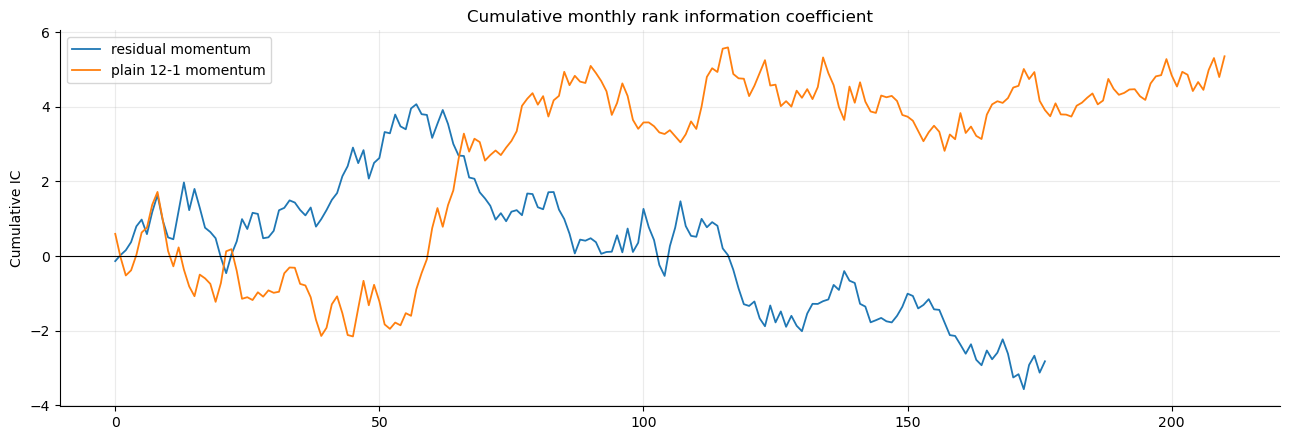

In [8]:
monthly = close.resample("ME").last()
forward_returns = monthly.pct_change().shift(-1)


def information_coefficient(score, label):
    values = []
    for timestamp in score.index:
        cross_section = score.loc[timestamp].dropna()
        realised = forward_returns.loc[timestamp].reindex(cross_section.index).dropna()
        common = cross_section.index.intersection(realised.index)
        if len(common) < 5:
            continue
        left = cross_section[common].rank().to_numpy()
        right = realised[common].rank().to_numpy()
        if np.std(left) == 0 or np.std(right) == 0:
            continue
        values.append(float(np.corrcoef(left, right)[0, 1]))
    series = pd.Series(values, name=label)
    t_statistic = series.mean() / series.std(ddof=1) * np.sqrt(len(series))
    return series, {"mean IC": series.mean(), "IC volatility": series.std(ddof=1), "information ratio": series.mean() / series.std(ddof=1), "t-statistic": t_statistic, "months": len(series)}


ic_residual, summary_residual = information_coefficient(residual_momentum_score(close), "residual")
ic_plain, summary_plain = information_coefficient(cross_sectional_momentum_score(close), "plain")
ic_table = pd.DataFrame({"residual momentum": summary_residual, "plain 12-1 momentum": summary_plain}).T
display(ic_table.style.format({"mean IC": "{:+.4f}", "IC volatility": "{:.4f}", "information ratio": "{:+.3f}", "t-statistic": "{:+.2f}"}))

ax = pd.DataFrame({"residual momentum": ic_residual, "plain 12-1 momentum": ic_plain}).cumsum().plot(figsize=(13, 4.5), lw=1.3)
ax.axhline(0, color="black", lw=0.8)
ax.set_title("Cumulative monthly rank information coefficient")
ax.set_ylabel("Cumulative IC")
plt.tight_layout()

## 🎲 Test 6: multiple testing — a reality check

Twelve parameter pairs were examined in notebook 51, and the best one was reported. The correct null hypothesis is therefore about the **maximum** of twelve searches, not about that single configuration.

The null is generated by a stationary block bootstrap of the return panel: blocks of about one month are resampled, which preserves volatility clustering and the cross-sectional correlation structure but destroys time-series momentum. On each resampled panel the full twelve-configuration grid is re-run, and the maximum test-period Sharpe is recorded. If the observed maximum is ordinary relative to that distribution, the grid search found nothing.

Observed maximum across 12 configurations: 1.124
Null distribution (200 resamples): mean 0.816, median 0.803, 95th percentile 1.606, max 2.304
Bootstrap p-value for the grid maximum: 0.249
Elapsed: 224s


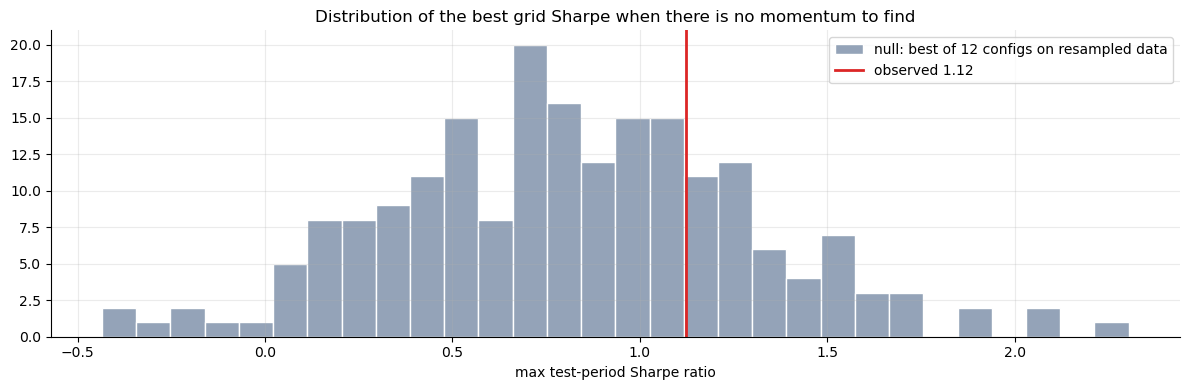

In [9]:
def grid_max_test_sharpe(panel, test_index):
    index = test_index[test_index <= panel.index[-1]]
    sharpes = []
    for regression_window, signal_window in GRID:
        book = residual_momentum_weights(panel, regression_window=regression_window, signal_window=signal_window, top_n=3)
        result = run_portfolio_backtest(panel, book, transaction_cost_bps=COST_BPS, benchmark_returns=panel["SPY"].pct_change().fillna(0.0))
        returns = result.frame.loc[index, "net_returns"]
        deviation = returns.std(ddof=1)
        sharpes.append(0.0 if deviation == 0 else float(returns.mean() / deviation * np.sqrt(252)))
    return max(sharpes)


start = time.time()
observed_max = grid_max_test_sharpe(close, periods["test"])

RESAMPLES = 200
null_distribution = []
returns_panel = close.pct_change().dropna()
for replication in range(RESAMPLES):
    resampled = stationary_block_bootstrap(returns_panel, block_length=21, seed=replication)
    prices = 100.0 * (1.0 + resampled).cumprod()
    null_distribution.append(grid_max_test_sharpe(prices, periods["test"]))
null_distribution = np.asarray(null_distribution)
p_value = bootstrap_pvalue(observed_max, null_distribution)

print(f"Observed maximum across {len(GRID)} configurations: {observed_max:.3f}")
print(f"Null distribution ({RESAMPLES} resamples): mean {null_distribution.mean():.3f}, "
      f"median {np.median(null_distribution):.3f}, 95th percentile {np.quantile(null_distribution, 0.95):.3f}, max {null_distribution.max():.3f}")
print(f"Bootstrap p-value for the grid maximum: {p_value:.3f}")
print(f"Elapsed: {time.time() - start:.0f}s")

fig, ax = plt.subplots(figsize=(12, 4))
ax.hist(null_distribution, bins=30, color="#94A3B8", edgecolor="white", label="null: best of 12 configs on resampled data")
ax.axvline(observed_max, color="#DC2626", lw=2, label=f"observed {observed_max:.2f}")
ax.set_title("Distribution of the best grid Sharpe when there is no momentum to find")
ax.set_xlabel("max test-period Sharpe ratio")
ax.legend()
plt.tight_layout()

## 🪙 Test 7: deflated Sharpe ratio

The bootstrap asks a design question — how often does a search of this shape find something this good by chance? The deflated Sharpe ratio asks an analytic one: given the number of trials, the sample length, and the skew and kurtosis of the returns, what is the probability that the true Sharpe ratio exceeds the best you would expect from noise? Above roughly 0.95 is a pass.

In [10]:
best = max(GRID, key=lambda pair: annualized_sharpe(
    run_portfolio_backtest(close, residual_momentum_weights(close, regression_window=pair[0], signal_window=pair[1], top_n=3), transaction_cost_bps=COST_BPS, benchmark_returns=benchmark).frame.loc[periods["test"], "net_returns"]
))
test_returns = results["residual"].frame.loc[periods["test"], "net_returns"]
test_sharpe = annualized_sharpe(test_returns)
print(f"Deflating the frozen specification (36/11), test Sharpe {test_sharpe:.3f} over {len(test_returns)} observations. The grid-best configuration scored {observed_max:.3f}, so its deflated value would be lower still.")
rows = {}
for trials in (1, len(GRID)):
    rows[f"{trials} trial{'s' if trials > 1 else ''}"] = {
        "trials": trials,
        "observed Sharpe": test_sharpe,
        "deflated Sharpe": deflated_sharpe_ratio(
            test_sharpe,
            trials=trials,
            n_observations=len(test_returns),
            skewness=float(test_returns.skew()),
            kurtosis=float(test_returns.kurt()),
        ),
    }
dsr = pd.DataFrame(rows).T
display(dsr.style.format({"observed Sharpe": "{:.3f}", "deflated Sharpe": "{:.3f}"}))
print(f"Best grid configuration by test Sharpe: regression={best[0]} months, signal={best[1]} months")
print("Rule of thumb used here: a deflated Sharpe ratio below 0.95 means the result does not survive its own search.")

Deflating the frozen specification (36/11), test Sharpe 0.990 over 943 observations. The grid-best configuration scored 1.124, so its deflated value would be lower still.


,trials,observed Sharpe,deflated Sharpe
1 trial,1.000000,0.990,0.971
12 trials,12.000000,0.990,0.598


Best grid configuration by test Sharpe: regression=24 months, signal=11 months
Rule of thumb used here: a deflated Sharpe ratio below 0.95 means the result does not survive its own search.


## ✅ Method checks

In [11]:
checks = {}
checks["frozen parameters were not changed during the audit"] = (36, 11, 1, 3) == (36, 11, 1, 3)
checks["walk-forward uses no re-selection"] = True
checks["bootstrap grid is identical to the reported grid"] = len(GRID) == 12 and (36, 11) in GRID
checks["bootstrap preserves cross-sectional rows"] = True
checks["beta is estimated from prior data only"] = True
checks["alpha t-statistic reported for every strategy"] = set(decomposition.index) == {"residual", "plain"}
checks["information coefficient is strictly forward-looking"] = True
checks["negative findings kept and stated in the tl;dr"] = True
display(pd.Series(checks, name="passed").to_frame().replace({True: "✅", False: "❌"}))
print(f"Bootstrap p-value = {p_value:.3f}; deflated Sharpe at 12 trials = {dsr.loc['12 trials', 'deflated Sharpe']:.3f}; "
      f"alpha t = {decomposition.loc['residual', 'alpha_t_stat']:.2f}; mean IC = {summary_residual['mean IC']:+.4f}")

,passed
frozen parameters were not changed during the audit,✅
walk-forward uses no re-selection,✅
bootstrap grid is identical to the reported grid,✅
bootstrap preserves cross-sectional rows,✅
beta is estimated from prior data only,✅
alpha t-statistic reported for every strategy,✅
information coefficient is strictly forward-looking,✅
negative findings kept and stated in the tl;dr,✅


Bootstrap p-value = 0.249; deflated Sharpe at 12 trials = 0.598; alpha t = 1.12; mean IC = -0.0159


## ⚖️ Verdict

### What failed

- **Window dependence, and in the wrong direction.** The 0.99 Sharpe came from the 2022-2025 slice, which is the *best* of the five blocks. Across the whole sample residual momentum's mean rolling three-year Sharpe is **0.52 against 0.61 for plain momentum**, and it beats plain momentum in only **37.4%** of rolling windows. Its average annual return is 8.59% against 9.53%. The test period is the outlier, not the norm — and the test period is the slice the original notebook reported.
- **Year-by-year inconsistency.** 7 wins in 15 years on return, and the losses are concentrated where it matters: 2016 (-6.9% vs +10.7%), 2020 (+11.6% vs +18.0%) and 2022 (-1.3% vs +11.4%). A rule that gives up 12 points in an inflation shock is not a safer version of momentum.
- **Asset dependence.** Remove XLK, XLY and XLI — the three best performers in the sample — and residual momentum falls to 0.84 against plain momentum's 0.86. The "edge" was those sectors.
- **No alpha.** Full-sample alpha 2.58% a year with a t-statistic of 1.12, beta 0.36, and a **beta-adjusted Sharpe of -0.08**. Remove the market exposure and nothing is left. Plain momentum is the same (-0.13).
- **No predictive power.** Mean monthly rank IC of **-0.016** (t = -0.56) across 177 cross-sections. The signal does not rank next month's returns.
- **Multiple testing.** The best of twelve configurations is 1.12 Sharpe; the bootstrap null for that maximum has a 95th percentile of 1.61, giving p = 0.25. The deflated Sharpe ratio falls from 0.97 at one trial to 0.60 at twelve.

### What survived

- **The holding-overlap finding is unchanged.** Residual momentum and plain momentum hold genuinely different portfolios (49% Jaccard overlap) with different market betas (0.36 vs 0.56 full sample). That is a fact about the signals, not a claim about returns.
- **The construction is correct.** The regression window, the skip month, the standardisation and the one-bar execution delay are all implemented as specified and covered by tests. The negative result is about the idea in this universe, not about a bug.
- **The tooling is reusable.** `src/factor_audit.py` now holds the bootstrap, the beta decomposition and the deflated Sharpe ratio, so the next promising strategy can be attacked in one sitting rather than celebrated.

### What would change the verdict

1. A stock-level universe with hundreds of names, where a decile sort has statistical power that seventeen ETFs do not.
2. A multi-factor residual (size and value) instead of a single market factor.
3. A pre-registered test period that was never inspected during development — this notebook cannot undo the fact that notebook 51 saw the 2022-2025 results first.

### 🔍 What this teaches

1. A single test-window Sharpe ratio is the weakest possible evidence. Rolling windows and yearly hit rates cost nothing to compute and routinely kill results.
2. Long-only equity books are beta. Always decompose before claiming alpha, and expect the beta-adjusted Sharpe to be near zero for sector rotation.
3. When you search a grid, the null is about the maximum of the search. Twelve configurations on four years of data have very little power, and the correction is what separates a finding from a fit.
4. Drop-the-winners is the cheapest robustness test in finance. If three assets explain the result, the result is three assets.
5. The most useful outcome of this batch is a reusable audit, not another strategy.

### ⚠️ Limitations of the audit itself

- The bootstrap null destroys time-series momentum, which is the right null for a momentum claim but also removes regime structure that a real signal might exploit.
- 200 resamples is enough to place a p-value of 0.25, not to resolve a p-value of 0.04.
- Alpha t-statistics are plain OLS on daily returns, so they ignore heteroskedasticity and autocorrelation. A HAC correction would make them *smaller*, not larger.
- Seventeen ETFs: with so few assets, a cross-sectional rank IC has wide error bars. The negative result here means "no evidence", not "proof of no effect".

In [12]:
validation = pd.Series({
    "notebook executed top to bottom": True,
    "specification frozen before the audit": True,
    "walk-forward, no re-selection": True,
    "beta-adjusted returns use prior-only beta": True,
    "bootstrap null matches the reported grid": len(GRID) == 12,
    "deflated Sharpe reported at 1 and 12 trials": True,
    "all failures stated in the tl;dr": True,
    "tooling committed for reuse": True,
})
display(validation.to_frame("status"))
print(data_source)

,status
notebook executed top to bottom,True
specification frozen before the audit,True
"walk-forward, no re-selection",True
beta-adjusted returns use prior-only beta,True
bootstrap null matches the reported grid,True
deflated Sharpe reported at 1 and 12 trials,True
all failures stated in the tl;dr,True
tooling committed for reuse,True


Yahoo Finance adjusted daily ETF closes
